In [102]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

In [103]:
df = pd.read_csv('ENFR 2018 - Base usuario.txt', sep='|')

In [104]:
def calcular_porcentaje_nulos(df):
    porcentaje_nulos = (df.isnull().mean() * 100).round(2)
    porcentaje_nulos = porcentaje_nulos[porcentaje_nulos > 0].sort_values(ascending=False)
    return porcentaje_nulos

## Contexto dataset

### Encuesta Nacional de Factores de Riesgo (ENFR) 2018

El objetivo de esta encuesta, realizada por el INDEC, es estudiar los comportamientos y condiciones de vida que pueden afectar la salud de la población de 18 años y más, así como algunas características de las viviendas y de los hogares donde residen.

## Analisis de columnas

In [105]:
df.columns

Index(['id', 'cod_provincia', 'region', 'tamanio_aglomerado', 'aglomerado',
       'localidades_150', 'submuestra', 'bhcv01', 'bhcv02', 'bhcv03',
       ...
       'glucemia_elevada', 'prevalencia_glucemia_elevada_combinada',
       'findrisc', 'bimq06', 'bimq06_01', 'colesterol_elevado',
       'prevalencia_colesterol_combinada', 'wf1p', 'wf2p', 'wf3p'],
      dtype='str', length=287)

In [106]:
df[["bhcv03"]].value_counts()

bhcv03
1         25088
2          3860
3           208
4            68
Name: count, dtype: int64

#### Link donde se explica a detalle cada columna con su valor asociado: https://www.indec.gob.ar/ftp/cuadros/menusuperior/enfr/manual_base_usuario_enfr2018.pdf

- **id, cod_provincia, region, tamanio_aglomerado, aglomerado:** Identifican dónde vive la persona

- **bhcv01–bhcv11:** Bloque de características de la vivienda.

- **bhho01–bhho03:** Características del hogar.

- **cant_componentes, miembros_18, tipo_hogar:** Composición del hogar.

- **bhih01, rango_ingreso, quintil_uc:** Ingresos y nivel económico del hogar.

- **bhch...:** Datos sociodemográficos, como edad, educación y cobertura de salud.

- **bisl..., bisg...:** Variables de salud y otros aspectos sociodemográficos.

- **biaf...:** Actividad física y sus barreras.

- **bita...:** Tabaco y aspectos relacionados con su consumo.

- **biha...:** Hipertensión arterial.

- **bipc..., imc, imc_categorias:** Peso, talla e índice de masa corporal.

- **bial...:** Alimentación y consumo de frutas y verduras.

- **bico...:**  Colesterol.

- **bica..., consumo_regular_riesgo:** Consumo de alcohol y patrones de riesgo.

- **bidi...:** Diabetes.

- **bile..., bipp..., bicc...:** Otros controles de salud, prevención y detección de enfermedades.

- **bima..., bimq...:** Mediciones físicas y bioquímicas de la submuestra.

- **wf1p, wf2p, wf3p:** Variables de ponderación o factores de expansión; hay que consultar el diccionario para distinguirlas.

In [107]:
df["wf1p"].value_counts()

wf1p
189     58
150     57
227     56
126     55
154     55
        ..
1832     1
2184     1
26       1
2088     1
1414     1
Name: count, Length: 4175, dtype: int64

In [108]:
df.head()

,id,cod_provincia,region,tamanio_aglomerado,aglomerado,localidades_150,submuestra,bhcv01,bhcv02,bhcv03,...,glucemia_elevada,prevalencia_glucemia_elevada_combinada,findrisc,bimq06,bimq06_01,colesterol_elevado,prevalencia_colesterol_combinada,wf1p,wf2p,wf3p
0,1128639,2,1,1,1,1,1,3,2,1,...,NaN,NaN,2.0,NaN,NaN,NaN,NaN,2378,4464,0
1,1709939,2,1,1,1,1,0,1,4,1,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3588,0,0
2,6874130,2,1,1,1,1,0,3,2,1,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2740,0,0
3,10319375,2,1,1,1,1,1,3,1,1,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,493,0,0
4,11140857,2,1,1,1,1,0,3,3,1,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2016,0,0


## Nulos

In [109]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 29224 entries, 0 to 29223
Columns: 287 entries, id to wf3p
dtypes: float64(186), int64(101)
memory usage: 64.0 MB


### El dataset tiene 29.224 registros con 287 columnas

In [110]:
porcentaje_nulos = (df.isnull().sum() / len(df)) * 100

columnas_con_nulos = porcentaje_nulos[porcentaje_nulos > 0].sort_values(ascending=False)

df_nulos = pd.DataFrame({'Porcentaje de Nulos (%)': columnas_con_nulos})

df_nulos.head(32)

,Porcentaje de Nulos (%)
bita06_b_99,99.941829
biha06_99,99.921298
biaf02_99,99.869970
biha11_99,99.842595
biaf04_99,99.811799
bita02_99,99.562004
bimq05_01,99.510676
bica03_99,99.473036
bhch10_99,99.473036
bhch10_99_j,99.469614


#### Hay columnas con muchos nulos, podemos ver que hay 17 columnas con mas del 99% de nulos

## Variables de interes

In [111]:
columnas_elegidas = [
    'bhch03', 'bhch04', 'region', 'nivel_instruccion_agrupado', 'cobertura_salud',                                  # Sociodemográfica y Socioeconómica
    'nivel_actividad_fisica', 'biaf07_m', 'promedio_fv_diario', 'consumo_tabaco_100', 'consumo_episodico_excesivo', 'quintil_uc', 'condicion_actividad', # Hábitos y Estilo de Vida
    'bisg01', 'imc', 'prevalencia_hipertension', 'prevalencia_diabetes', 'control_hipertension',                  # Salud General y Condiciones Crónicas
    'bima10', 'bima07'                                          # Mediciones Físicas y Bioquímicas Objetivas
]

df = df[columnas_elegidas]

In [112]:
df = df.rename(columns={
    'bhch03': 'sexo',
    'bhch04': 'edad',
    'biaf07_m': 'minutos_diarios_sentado',
    'promedio_fv_diario': 'porciones_diarias_de_frutas_verduras',
    'bisg01': 'percepcion_estado_de_salud',
    'bima10': 'peso',
    'bima07': 'altura',
    'quintil_uc' : 'quintil_ingresos'
})

#### Sociodemográfica y Socioeconómica
- **sexo** (`bhch03`): Sexo
- **edad** (`bhch04`): Edad
- **region**: Región geográfica
- **nivel_instruccion_agrupado**: Nivel educativo alcanzado
- **cobertura_salud**: Cobertura médica
- **quintil_ingresos**: Nivel de ingresos

#### Hábitos y Estilo de Vida
- **nivel_actividad_fisica**: Nivel de actividad física
- **minutos_diarios_sentado** (`biaf07_m`): Minutos diarios que pasa sentado
- **porciones_diarias_de_frutas_verduras** (`promedio_fv_diario`): Porciones diarias de frutas y verduras
- **consumo_tabaco_100**: Consumo de tabaco
- **consumo_episodico_excesivo**: Consumo episódico excesivo de alcohol
- **condicion_actividad**: Si la persona está ocupada, desocupada o inactiva.

#### Salud General y Condiciones Crónicas
- **percepcion_estado_de_salud** (`bisg01`): Percepción del estado general de salud
- **imc**: Índice de masa corporal por autorreporte
- **prevalencia_hipertension**: Presión arterial elevada según autorreporte
- **prevalencia_diabetes**: Diabetes según autorreporte

#### Mediciones Físicas y Bioquímicas Objetivas
- **peso** (`bima10`): Medición del peso en kilogramos
- **altura** (`bima07`): Altura en centímetros
- **control_hipertension**: Si se controló la presión arterial en los últimos 2 años.

In [113]:
df.dtypes

sexo                                      int64
edad                                      int64
region                                    int64
nivel_instruccion_agrupado                int64
cobertura_salud                           int64
nivel_actividad_fisica                  float64
minutos_diarios_sentado                 float64
porciones_diarias_de_frutas_verduras    float64
consumo_tabaco_100                        int64
consumo_episodico_excesivo              float64
quintil_ingresos                          int64
condicion_actividad                       int64
percepcion_estado_de_salud                int64
imc                                     float64
prevalencia_hipertension                float64
prevalencia_diabetes                      int64
control_hipertension                      int64
peso                                    float64
altura                                  float64
dtype: object

In [127]:
mapeo_categorias = {
    'sexo': {1: 'Varon', 2: 'Mujer'},
    'region': {
        1: 'Metropolitana',
        2: 'Pampeana',
        3: 'Noroeste',
        4: 'Noreste',
        5: 'Cuyo',
        6: 'Patagónica'
    },
    'quintil_ingresos': {
        1: 'Muy bajos (20% de menores ingresos)',
        2: 'Bajos (20% a 40%)',
        3: 'Medios (40% a 60%)',
        4: 'Altos (60% a 80%)',
        5: 'Muy altos (20% de mayores ingresos)'
    },
    'prevalencia_hipertension': {
        1: 'Si',
        2: 'No',
        99: 'NS/NR'
    },
    'prevalencia_diabetes': {
        1: 'Si',
        2: 'No',
        99: 'NS/NR'
    },
    'nivel_instruccion_agrupado': {
        1: 'Hasta primario incompleto',
        2: 'Hasta secundario incompleto',
        3: 'Secundario completo y más'
    },
    'cobertura_salud': {
        1: 'Con obra social',
        2: 'Solo cobertura publica'
    },
    'nivel_actividad_fisica': {
        1: 'Alto',
        2: 'Medio',
        3: 'Bajo'
    },
    'consumo_tabaco_100': {
        1: 'Fumador actual',
        2: 'Ex fumador',
        3: 'No fumador'
    },
    'consumo_episodico_excesivo': {
        1: 'Si',
        2: 'No'
    },
    'percepcion_estado_de_salud': {
        1: 'Excelente',
        2: 'Muy buena',
        3: 'Buena',
        4: 'Regular',
        5: 'Mala'
    },
    'condicion_actividad': {
        1: 'Ocupado',
        2: 'Desocupado',
        3: 'Inactivo'
    },
    'control_hipertension': {
        1: 'Si',
        2: 'No',
        99: 'NS/NR'
    }
}

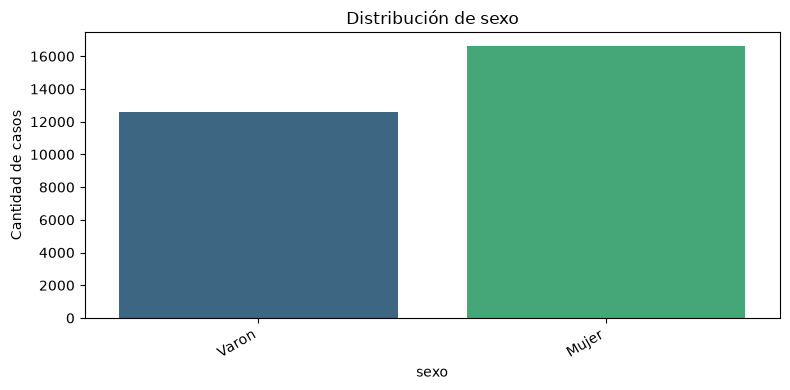

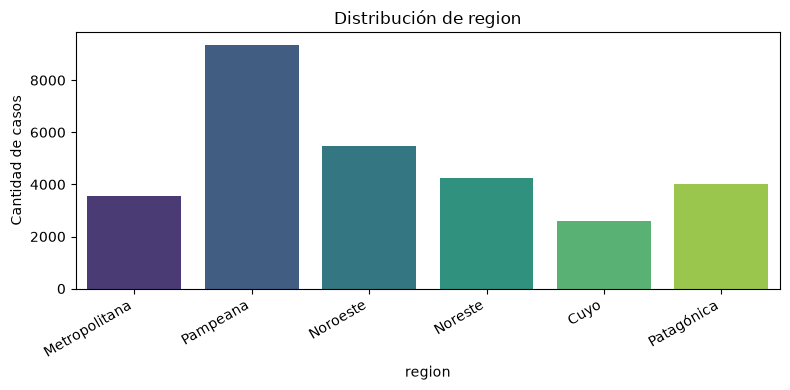

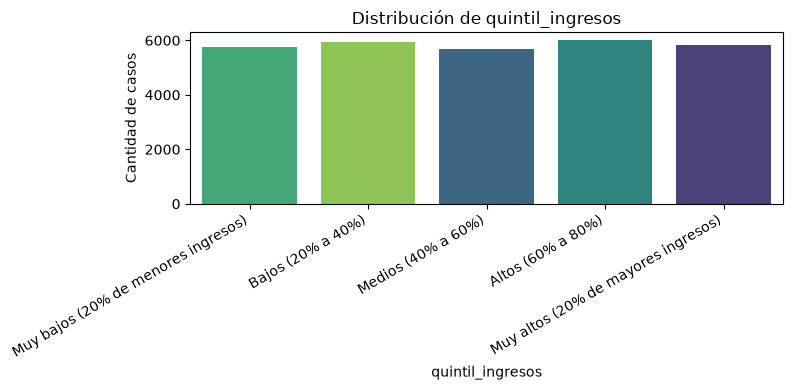

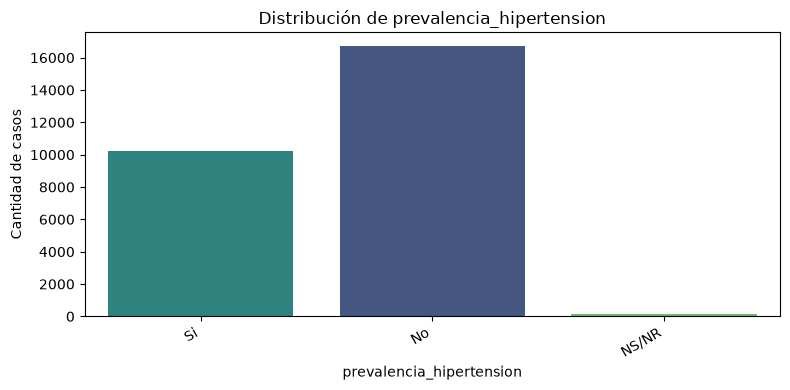

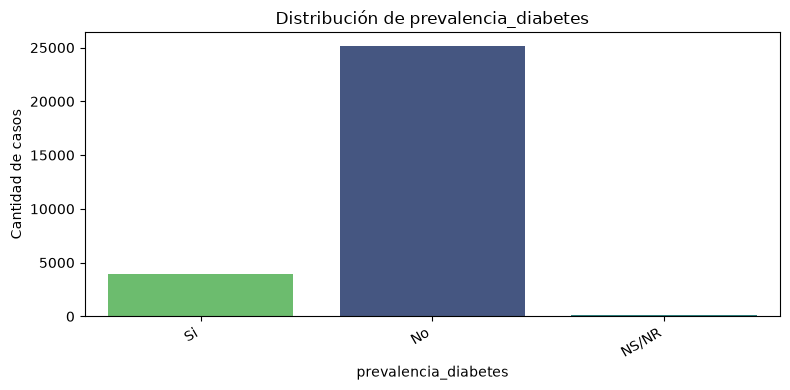

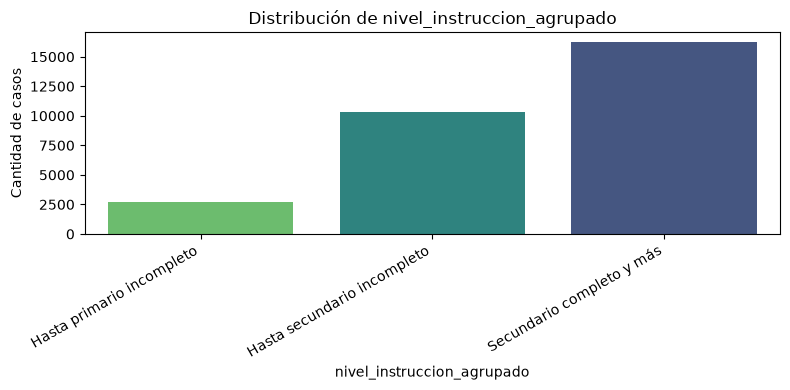

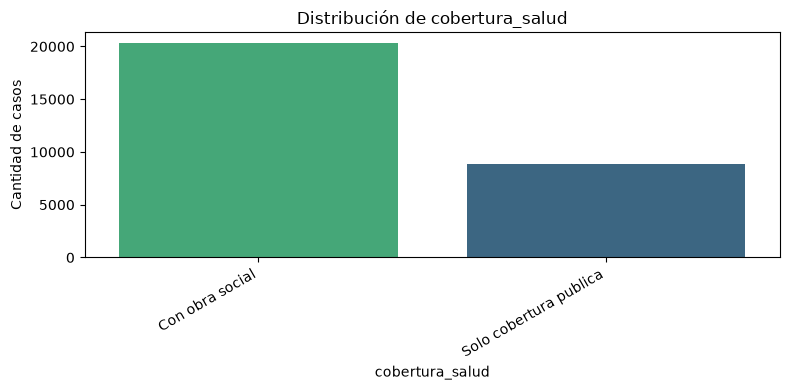

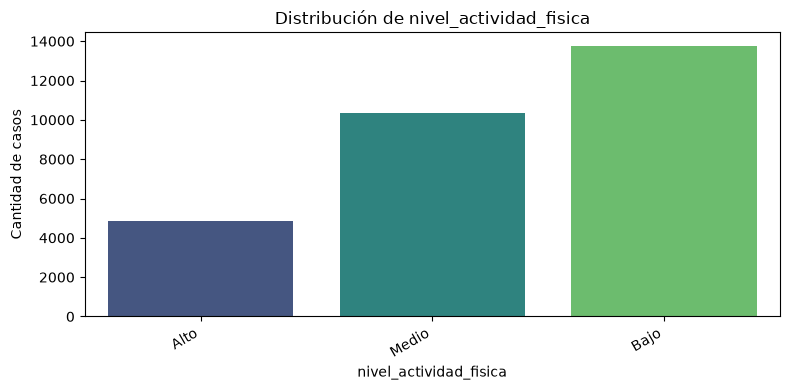

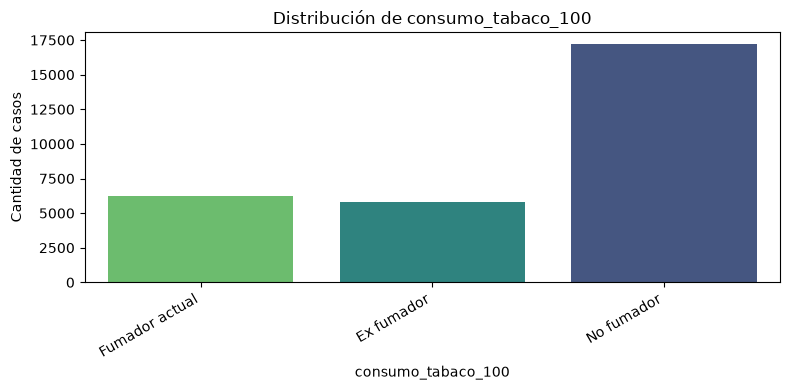

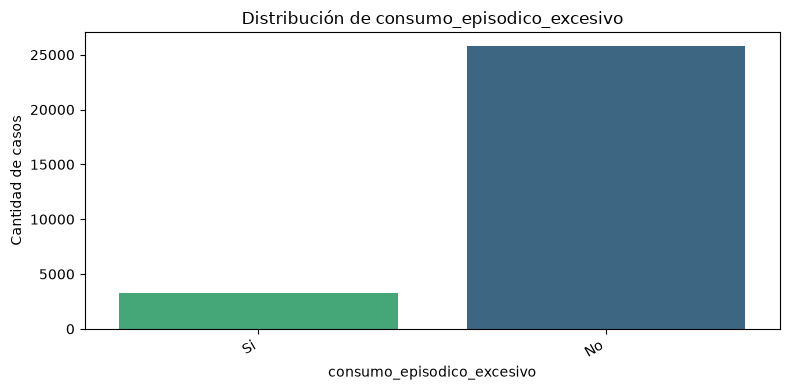

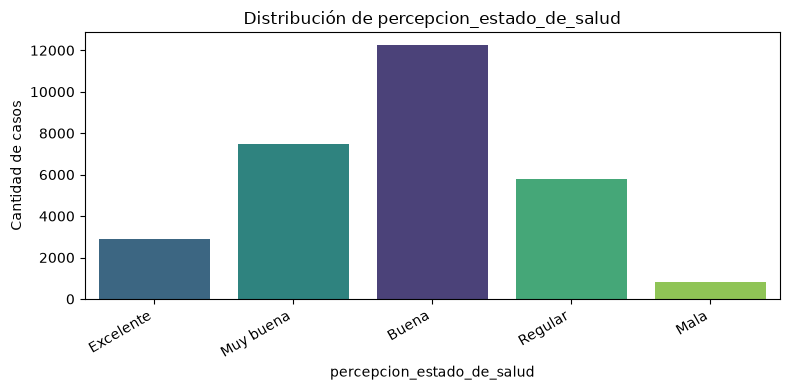

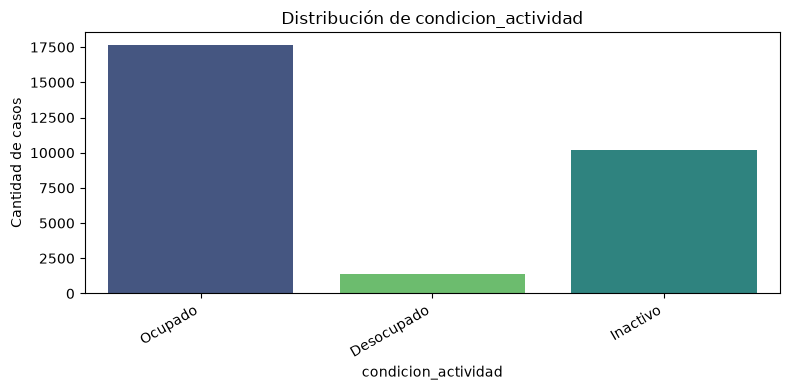

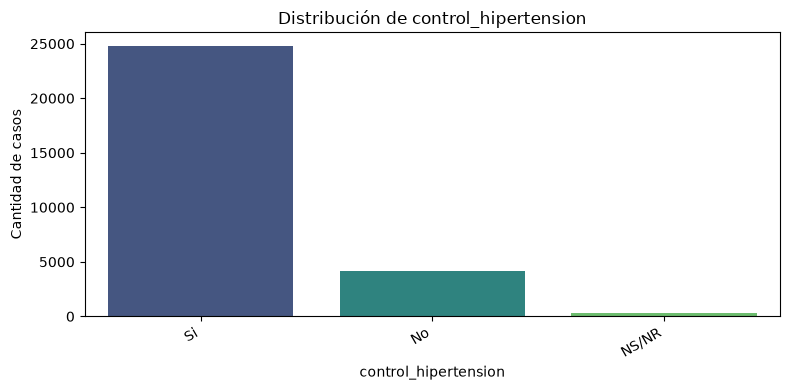

In [128]:
columnas_categoricas = list(mapeo_categorias.keys())

for col in columnas_categoricas:
    plt.figure(figsize=(8, 4))
    serie_etiquetas = df[col].map(mapeo_categorias[col])
    orden = list(mapeo_categorias[col].values())
    sns.countplot(x=serie_etiquetas, order=orden, hue=serie_etiquetas, palette='viridis', legend=False)
    plt.title(f'Distribución de {col}')
    plt.xticks(rotation=30, ha='right')
    plt.xlabel(col)
    plt.ylabel('Cantidad de casos')
    plt.tight_layout()
    plt.show()

In [129]:
cols_num = [col for col in df.select_dtypes(include=[np.number]).columns if col not in columnas_categoricas]

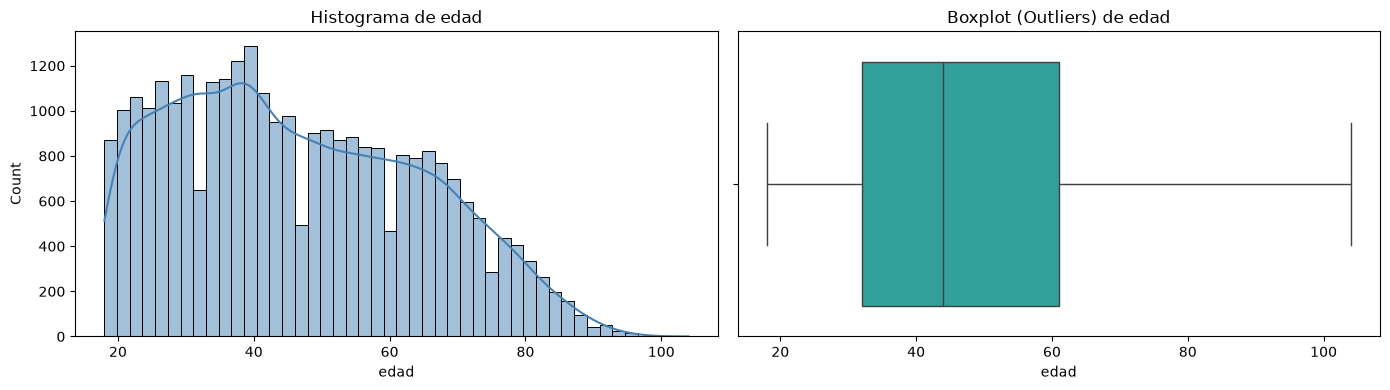

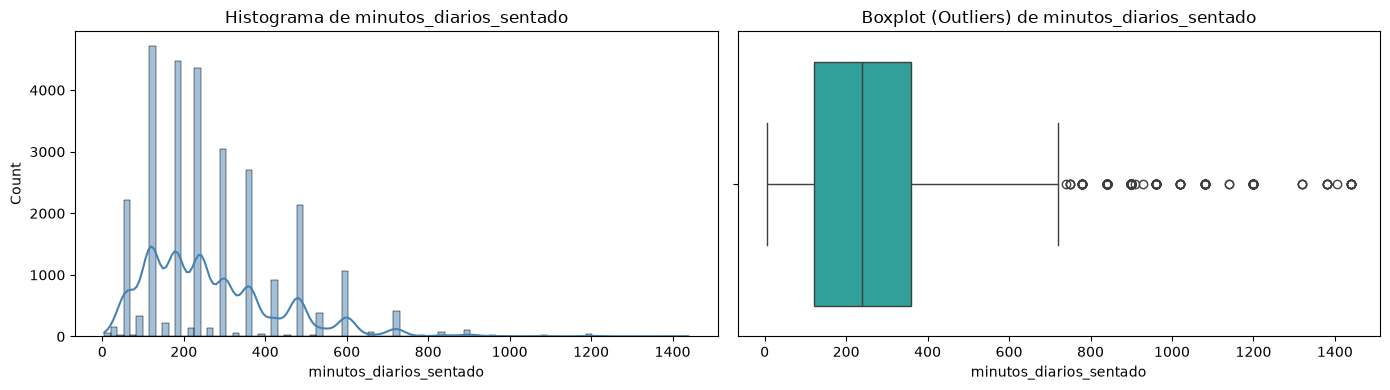

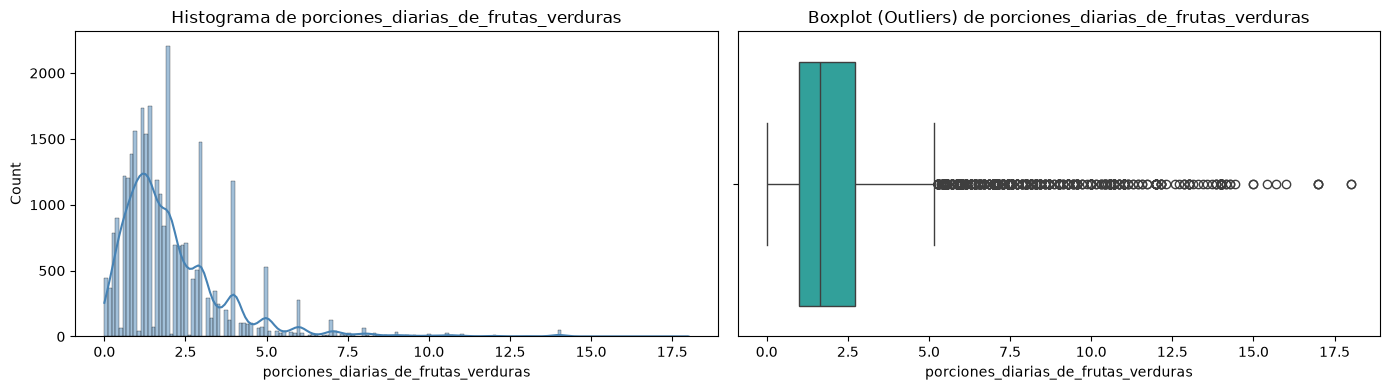

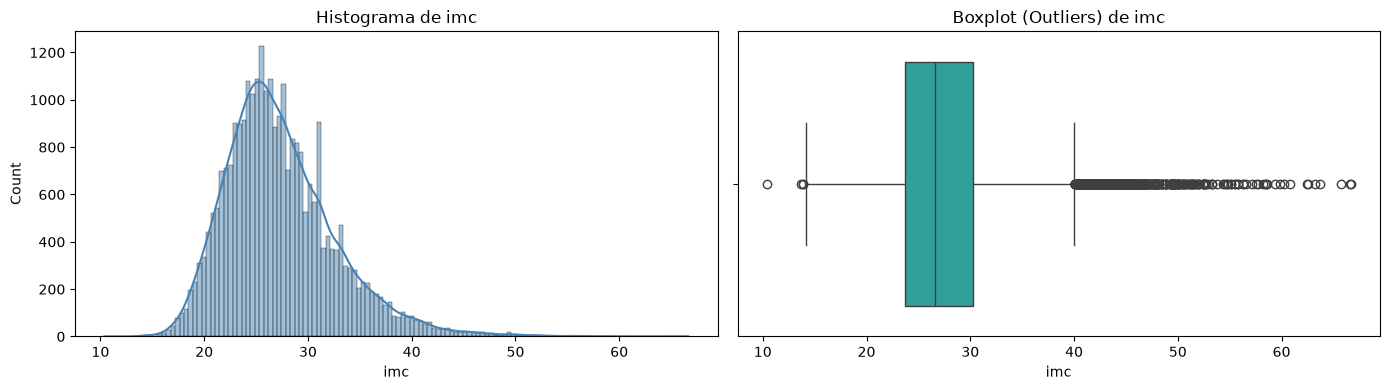

In [130]:
for col in cols_num:
    fig, axes = plt.subplots(1, 2, figsize=(14, 4))
    
    # Histograma con curva de densidad
    sns.histplot(df[col].dropna(), kde=True, ax=axes[0], color='steelblue')
    axes[0].set_title(f'Histograma de {col}')
    
    # Boxplot para ver outliers (Punto 1)
    sns.boxplot(data=df, x=col, ax=axes[1], color='lightseagreen')
    axes[1].set_title(f'Boxplot (Outliers) de {col}')
    
    plt.tight_layout()
    plt.show()

## Analisis de nulos

In [118]:
df.isnull().sum()

sexo                                        0
edad                                        0
region                                      0
nivel_instruccion_agrupado                  0
cobertura_salud                             0
nivel_actividad_fisica                    254
minutos_diarios_sentado                  1110
porciones_diarias_de_frutas_verduras      753
consumo_tabaco_100                          0
consumo_episodico_excesivo                154
quintil_ingresos                            0
condicion_actividad                         0
percepcion_estado_de_salud                  0
imc                                      2229
prevalencia_hipertension                 2082
prevalencia_diabetes                        0
control_hipertension                        0
peso                                    12799
altura                                  12733
dtype: int64

In [119]:
calcular_porcentaje_nulos(df)

peso                                    43.80
altura                                  43.57
imc                                      7.63
prevalencia_hipertension                 7.12
minutos_diarios_sentado                  3.80
porciones_diarias_de_frutas_verduras     2.58
nivel_actividad_fisica                   0.87
consumo_episodico_excesivo               0.53
dtype: float64

imc, peso y altura estan correlacionadas, por lo tanto lo mejor es rellenar cuando solo tenemos 1 columna nula

In [120]:
filas_rescatables = (df[['peso', 'altura', 'imc']].isnull().sum(axis=1) == 1).sum()
print(f"Filas que se pueden calcular exactas: {filas_rescatables}")

Filas que se pueden calcular exactas: 1599


In [121]:
# 1. Si falta IMC, pero tenemos peso y altura
df['imc'] = df['imc'].fillna(df['peso'] / ((df['altura'] / 100) ** 2))

# 2. Si falta PESO, pero tenemos imc y altura
df['peso'] = df['peso'].fillna(df['imc'] * ((df['altura'] / 100) ** 2))

# 3. Si falta ALTURA, pero tenemos peso e imc (multiplicamos por 100 para volver a cm)
df['altura'] = df['altura'].fillna(np.sqrt(df['peso'] / df['imc']) * 100)

In [122]:
calcular_porcentaje_nulos(df)

peso                                    43.58
altura                                  43.53
prevalencia_hipertension                 7.12
minutos_diarios_sentado                  3.80
porciones_diarias_de_frutas_verduras     2.58
imc                                      2.41
nivel_actividad_fisica                   0.87
consumo_episodico_excesivo               0.53
dtype: float64

logramos reducir los nulos de imc de 7.6% a 2.41%, tambien lo logramos con peso y altura, pero no lo suficiente. La decision va a ser eliminar

In [123]:
df = df.drop(columns=['peso', 'altura'])

In [124]:
calcular_porcentaje_nulos(df)

prevalencia_hipertension                7.12
minutos_diarios_sentado                 3.80
porciones_diarias_de_frutas_verduras    2.58
imc                                     2.41
nivel_actividad_fisica                  0.87
consumo_episodico_excesivo              0.53
dtype: float64